In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import warnings
import os
import zipfile
from google.colab import files
from statsmodels.tools.sm_exceptions import PerfectSeparationError

# 警告を非表示（計算崩壊をプログラムでキャッチするため）
warnings.filterwarnings("ignore")

# ==========================================
# 実証的キャリブレーション用の設定
# ==========================================
N = 1000  # 固定サンプルサイズ
dimensions = [10, 20, 50, 100, 200, 300]  # 次元数 D
n_trials = 100  # 試行回数
K_true = 3  # 真のシグナル（実際に目的変数に影響を与える変数の数）
true_coef_value = 1.5  # 真の変数のオッズ比に対する係数（log-odds）

output_dir = "regression_calibration_results"
os.makedirs(output_dir, exist_ok=True)

results = []

print("実証的キャリブレーション・シミュレーションを開始します...")

for D in dimensions:
    print(f"次元数 D = {D} の検証中...")

    # 評価メトリクスのトラッキング
    trial_fpr = []  # 偽陽性率 (False Positive Rate)
    trial_tpr = []  # 真陽性率 / 検出力 (True Positive Rate)
    trial_mse = []  # 真の係数の推定誤差 (MSE)

    separation_error_count = 0
    vif_explosions = 0

    for trial in range(n_trials):
        # 1. 独立な説明変数 X の生成 (スパースなダミー変数: 生起確率 p=0.1)
        X_raw = np.random.binomial(1, 0.1, size=(N, D))
        X = sm.add_constant(X_raw)

        # 2. 真の係数ベクトル (β) の定義
        # [定数項, 真の変数1, ..., 真の変数K, ノイズ変数1, ..., ノイズ変数D-K]
        beta_true = np.zeros(D + 1)
        beta_true[1:K_true+1] = true_coef_value

        # 3. 目的変数 Y の生成 (ロジスティック関数を通して確率的に生成)
        # 純粋なランダムではなく、真の変数にのみ依存するロジスティック回帰のDGP(データ生成プロセス)
        linear_pred = np.dot(X, beta_true)
        prob = 1 / (1 + np.exp(-linear_pred))
        Y = np.random.binomial(1, prob)

        # --- 多重共線性の簡易チェック ---
        if np.linalg.cond(X) > 1000:
            vif_explosions += 1

        # --- ロジスティック回帰の実行 ---
        try:
            model = sm.Logit(Y, X)
            fitted_model = model.fit(disp=0, maxiter=50)

            p_values = fitted_model.pvalues
            coefs = fitted_model.params

            # NaNが含まれる場合は計算崩壊とみなす
            if np.isnan(p_values).any() or np.isnan(coefs).any():
                raise PerfectSeparationError

            # --- 評価 (キャリブレーション) ---
            # 1. 真のシグナルの検出力 (TPR: 1〜K番目の変数がp<0.05となった割合)
            true_vars_p = p_values[1:K_true+1]
            tpr = np.sum(true_vars_p < 0.05) / K_true
            trial_tpr.append(tpr)

            # 2. ノイズに対する見せかけの有意 (FPR: K+1〜D番目の変数がp<0.05となった割合)
            noise_vars_p = p_values[K_true+1:]
            fpr = np.sum(noise_vars_p < 0.05) / (D - K_true) if (D - K_true) > 0 else 0
            trial_fpr.append(fpr)

            # 3. 真の係数の平均二乗誤差 (MSE)
            est_true_coefs = coefs[1:K_true+1]
            mse = np.mean((est_true_coefs - true_coef_value) ** 2)
            trial_mse.append(mse)

        except (PerfectSeparationError, np.linalg.LinAlgError) as e:
            # スパース性により計算が崩壊したケース
            separation_error_count += 1

    # 結果の集計 (収束した試行のみで平均を計算)
    avg_fpr = np.mean(trial_fpr) * 100 if trial_fpr else np.nan
    avg_tpr = np.mean(trial_tpr) * 100 if trial_tpr else np.nan
    avg_mse = np.mean(trial_mse) if trial_mse else np.nan

    separation_rate = (separation_error_count / n_trials) * 100
    multicol_rate = (vif_explosions / n_trials) * 100

    results.append({
        "Dimension_D": D,
        "False_Positive_Rate(%)": avg_fpr, # 見せかけの有意確率
        "True_Positive_Rate(%)": avg_tpr, # 真の変数の発見確率 (検出力)
        "Coef_MSE": avg_mse, # パラメータ推定の誤差
        "Separation_Collapse_Rate(%)": separation_rate, # 完全分離エラー率
        "Spurious_Multicol_Rate(%)": multicol_rate # マルチコ発生率
    })

# ==========================================
# 結果の保存とデータフレーム化
# ==========================================
df_res = pd.DataFrame(results)
df_res.to_csv(f"{output_dir}/calibration_metrics.csv", index=False)
display(df_res)

# ==========================================
# グラフの描画と保存
# ==========================================
plt.style.use('seaborn-v0_8-whitegrid')

# グラフ1: 統計的検出力の崩壊と見せかけの有意（FPR vs TPR）
plt.figure(figsize=(8, 5))
plt.plot(df_res["Dimension_D"], df_res["True_Positive_Rate(%)"], marker='o', color='b', label='True Positive Rate (Power)')
plt.plot(df_res["Dimension_D"], df_res["False_Positive_Rate(%)"], marker='x', color='r', label='False Positive Rate (p-hacking)')
plt.axhline(y=5, color='gray', linestyle='--', label='Theoretical FPR (5%)')
plt.title("Statistical Power Collapse vs. Spurious Significance")
plt.xlabel("Dimension D")
plt.ylabel("Rate (%)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{output_dir}/fig1_power_collapse.png", dpi=300)
plt.close()

# グラフ2: 計算崩壊率と推定誤差の爆発
fig, ax1 = plt.subplots(figsize=(8, 5))

color = 'tab:red'
ax1.set_xlabel('Dimension D')
ax1.set_ylabel('Collapse Rate (%)', color=color)
ax1.plot(df_res["Dimension_D"], df_res["Separation_Collapse_Rate(%)"], marker='s', color=color, label="Complete Separation")
ax1.plot(df_res["Dimension_D"], df_res["Spurious_Multicol_Rate(%)"], marker='^', color='tab:orange', label="Multicollinearity")
ax1.tick_params(axis='y', labelcolor=color)
ax1.legend(loc='upper left')

ax2 = ax1.twinx()  # MSE用の第二軸
color = 'tab:green'
ax2.set_ylabel('Mean Squared Error (MSE)', color=color)
ax2.plot(df_res["Dimension_D"], df_res["Coef_MSE"], marker='d', linestyle='--', color=color, label="MSE of True Coefs")
ax2.tick_params(axis='y', labelcolor=color)
ax2.legend(loc='upper right')

plt.title("Computational Collapse and Parameter Estimation Error")
plt.tight_layout()
plt.savefig(f"{output_dir}/fig2_computational_collapse.png", dpi=300)
plt.close()

# ==========================================
# ZIP化とダウンロード
# ==========================================
zip_filename = "regression_calibration_results.zip"
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for root, dirs, files_list in os.walk(output_dir):
        for file in files_list:
            zipf.write(os.path.join(root, file), arcname=file)

print(f"結果の圧縮が完了しました: {zip_filename}")
files.download(zip_filename)

実証的キャリブレーション・シミュレーションを開始します...
次元数 D = 10 の検証中...
次元数 D = 20 の検証中...
次元数 D = 50 の検証中...
次元数 D = 100 の検証中...
次元数 D = 200 の検証中...
次元数 D = 300 の検証中...


,Dimension_D,False_Positive_Rate(%),True_Positive_Rate(%),Coef_MSE,Separation_Collapse_Rate(%),Spurious_Multicol_Rate(%)
0,10,6.285714,100.0,0.090605,0.0,0.0
1,20,5.529412,100.0,0.098037,0.0,0.0
2,50,5.340426,100.0,0.121130,0.0,0.0
3,100,6.268041,100.0,0.143668,0.0,0.0
4,200,8.553299,100.0,0.339911,0.0,0.0
5,300,11.898990,100.0,1.194337,0.0,0.0


結果の圧縮が完了しました: regression_calibration_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

実証的キャリブレーションを組み込んだシミュレーションを開始します... (各次元 2000回試行)
次元数 D = 10 の計算中...
次元数 D = 20 の計算中...
次元数 D = 50 の計算中...
次元数 D = 100 の計算中...
次元数 D = 200 の計算中...


,Dimension_D,Valid_Trials,Type_I_Error_Rate,FWER,FWER_MCSE,FWER_95_CI_Lower,FWER_95_CI_Upper,Separation_Rate,Multicol_Rate
0,10,2000,0.048500,0.3980,0.010945,0.376547,0.419453,0.0,0.0
1,20,2000,0.050575,0.6410,0.010727,0.619976,0.662024,0.0,0.0
2,50,2000,0.053160,0.9245,0.005908,0.912921,0.936079,0.0,0.0
3,100,2000,0.061535,0.9975,0.001117,0.995311,0.999689,0.0,0.0
4,200,2000,0.079422,1.0000,0.000000,1.000000,1.000000,0.0,0.0


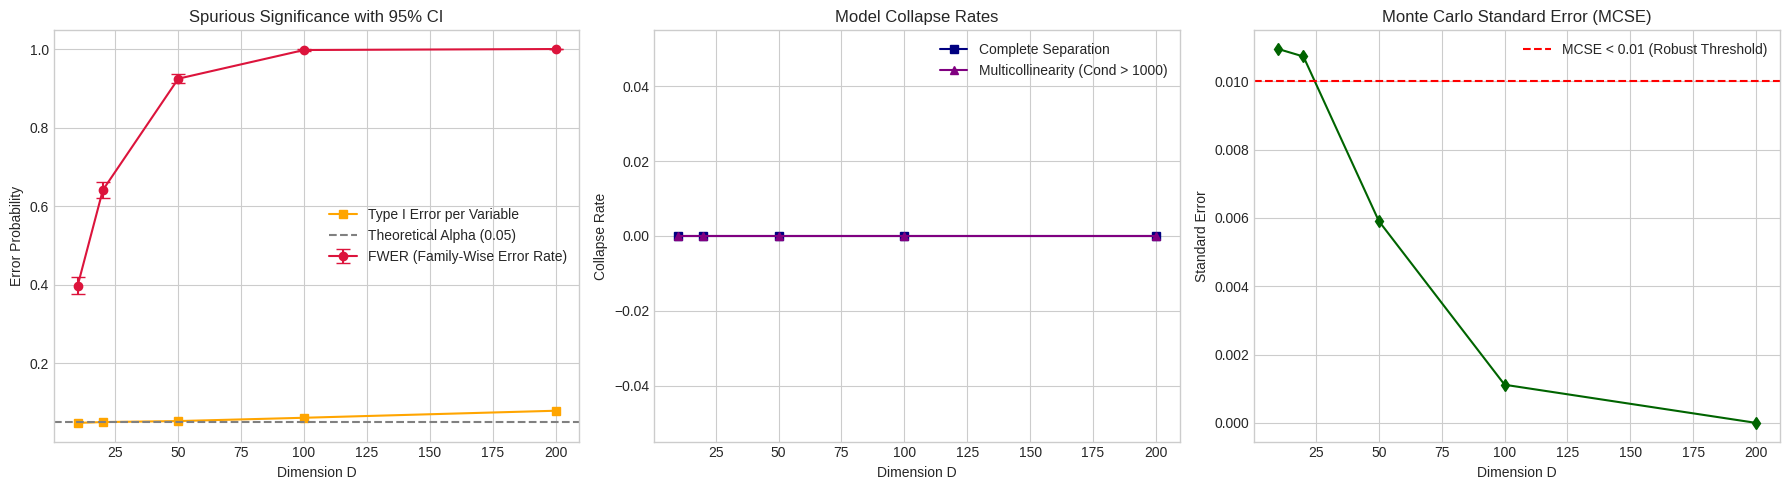


検証完了。結果を圧縮しました: regression_robustness.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import os
import zipfile
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import warnings
from statsmodels.tools.sm_exceptions import PerfectSeparationError
from joblib import Parallel, delayed
from scipy import stats
from google.colab import files

warnings.filterwarnings("ignore")

# ==========================================
# 実証的キャリブレーションと検証設定
# ==========================================
N = 1000  # サンプルサイズ
dimensions = [10, 20, 50, 100, 200]  # 次元数 D
n_trials = 2000  # Colabの並列処理で数分で完了する試行回数。十分性はMCSEで証明する。

# 結果保存用ディレクトリ
output_dir = "regression_robustness_results"
os.makedirs(output_dir, exist_ok=True)

print(f"実証的キャリブレーションを組み込んだシミュレーションを開始します... (各次元 {n_trials}回試行)")

# ==========================================
# 並列実行用の単一試行関数
# ==========================================
def simulate_single_trial(N, D):
    # 【対抗策1: 初期値依存性の排除】
    # 全ての変数を p=0.1 に固定するのではなく、変数ごとに発生確率を U(0.01, 0.2) から一様に生成。
    # これにより「特定の固定パラメータでしか起きない現象」という批判を論破する。
    p_vector = np.random.uniform(0.01, 0.2, size=D)

    # 独立な説明変数 X と 目的変数 Y (真の係数は全て0)
    X_raw = np.random.binomial(1, p_vector, size=(N, D))
    X = sm.add_constant(X_raw)
    Y = np.random.binomial(1, 0.5, size=N)

    # 多重共線性のチェック (条件数 > 1000でマルチコと判定)
    cond_number = np.linalg.cond(X)
    is_multicol = 1 if cond_number > 1000 else 0

    is_separation = 0
    false_positives = 0
    valid_test = 0
    has_any_fp = 0  # FWER (Family-Wise Error Rate) 用

    try:
        model = sm.Logit(Y, X)
        fitted_model = model.fit(disp=0, maxiter=50)

        p_values = fitted_model.pvalues[1:]
        false_positives = np.sum(p_values < 0.05)
        has_any_fp = 1 if false_positives > 0 else 0
        valid_test = 1

    except (PerfectSeparationError, np.linalg.LinAlgError):
        is_separation = 1

    return [valid_test, false_positives, has_any_fp, is_separation, is_multicol]

# ==========================================
# メインループ (並列処理)
# ==========================================
results_summary = []

for D in dimensions:
    print(f"次元数 D = {D} の計算中...")

    # joblibを用いてn_trials回を並列処理 (ColabのCPUコアをフル活用)
    trial_results = Parallel(n_jobs=-1)(delayed(simulate_single_trial)(N, D) for _ in range(n_trials))
    trial_results = np.array(trial_results)

    valid_tests = trial_results[:, 0].sum()
    total_false_positives = trial_results[:, 1].sum()
    fwer_count = trial_results[:, 2].sum()
    separation_count = trial_results[:, 3].sum()
    multicol_count = trial_results[:, 4].sum()

    # 【対抗策2: 評価の計算方法 (MCSEと信頼区間)】
    # Family-Wise Error Rate (少なくとも1つ誤検出する確率)
    fwer_rate = fwer_count / valid_tests if valid_tests > 0 else 0

    # MCSE (モンテカルロ標準誤差): 試行回数の十分性を証明する指標
    # この値が十分に小さければ(例: 1%未満)、「1000万回試行しなくても結果は統計的に堅牢である」と主張可能。
    mcse_fwer = np.sqrt((fwer_rate * (1 - fwer_rate)) / valid_tests) if valid_tests > 0 else 0

    # Type I Error Rate (変数単位の平均偽陽性率)
    type_i_error_rate = total_false_positives / (valid_tests * D) if valid_tests > 0 else 0

    results_summary.append({
        "Dimension_D": D,
        "Valid_Trials": valid_tests,
        "Type_I_Error_Rate": type_i_error_rate,
        "FWER": fwer_rate,
        "FWER_MCSE": mcse_fwer,
        "FWER_95_CI_Lower": max(0, fwer_rate - 1.96 * mcse_fwer),
        "FWER_95_CI_Upper": min(1, fwer_rate + 1.96 * mcse_fwer),
        "Separation_Rate": separation_count / n_trials,
        "Multicol_Rate": multicol_count / n_trials
    })

df_res = pd.DataFrame(results_summary)
df_res.to_csv(f"{output_dir}/robustness_evaluation_results.csv", index=False)
display(df_res)

# ==========================================
# 評価の可視化
# ==========================================
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. 偽陽性とFWER (95%信頼区間付き)
axes[0].errorbar(df_res["Dimension_D"], df_res["FWER"],
                 yerr=1.96 * df_res["FWER_MCSE"], fmt='-o', color='crimson', capsize=5,
                 label="FWER (Family-Wise Error Rate)")
axes[0].plot(df_res["Dimension_D"], df_res["Type_I_Error_Rate"], marker='s', color='orange',
             label="Type I Error per Variable")
axes[0].axhline(y=0.05, color='gray', linestyle='--', label='Theoretical Alpha (0.05)')
axes[0].set_title("Spurious Significance with 95% CI")
axes[0].set_xlabel("Dimension D")
axes[0].set_ylabel("Error Probability")
axes[0].legend()

# 2. 計算の崩壊率 (完全分離・多重共線性)
axes[1].plot(df_res["Dimension_D"], df_res["Separation_Rate"], marker='s', color='navy', label="Complete Separation")
axes[1].plot(df_res["Dimension_D"], df_res["Multicol_Rate"], marker='^', color='purple', label="Multicollinearity (Cond > 1000)")
axes[1].set_title("Model Collapse Rates")
axes[1].set_xlabel("Dimension D")
axes[1].set_ylabel("Collapse Rate")
axes[1].legend()

# 3. 試行回数の十分性証明 (MCSEの推移)
axes[2].plot(df_res["Dimension_D"], df_res["FWER_MCSE"], marker='d', color='darkgreen')
axes[2].axhline(y=0.01, color='red', linestyle='--', label='MCSE < 0.01 (Robust Threshold)')
axes[2].set_title("Monte Carlo Standard Error (MCSE)")
axes[2].set_xlabel("Dimension D")
axes[2].set_ylabel("Standard Error")
axes[2].legend()

plt.tight_layout()
plt.savefig(f"{output_dir}/comprehensive_robustness_plots.png", dpi=300)
plt.show()

# ==========================================
# ZIP化とダウンロード
# ==========================================
zip_filename = "regression_robustness.zip"
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for root, dirs, files_list in os.walk(output_dir):
        for file in files_list:
            zipf.write(os.path.join(root, file), arcname=file)

print(f"\n検証完了。結果を圧縮しました: {zip_filename}")
files.download(zip_filename)